# Multimodal Human Activity Recognition with IMU and Audio

This project compares deep learning models for recognizing everyday activities from smartwatch **IMU (accelerometer and gyroscope)** and **audio** recordings.

The experiment includes:
1. **Audio-only classification** with MobileNetV2.
2. **IMU-only classification** with a 1D convolutional network.
3. **Late fusion** by averaging audio and IMU logits.
4. **Bidirectional cross-attention fusion** over temporal audio and IMU features.
5. **Random forest activity detection** using statistical IMU features.

Continuous recordings contain labeled activities separated by background periods. Evaluation distinguishes **activity detection** (when an activity occurs) from **activity classification** (which activity occurs).



---
## Dataset Description

The dataset comes from a controlled lab study where participants wore a smartwatch and performed daily activities sequentially. We use **15 single-session recordings** (~30 minutes each).

### File Structure (per session)

Each session (e.g., `011`) has:
- **`{ID}.csv`** — Continuous IMU data (6 columns: `accel_x, accel_y, accel_z, gyro_x, gyro_y, gyro_z`), sampled at ~50 Hz, no header
- **`{ID}.wav`** — Continuous stereo audio at 22,050 Hz (preprocessing converts it to mono by averaging channels)
- **`{ID}ant.csv`** — Tab-separated annotation file. The columns the loader uses are `Start (ms)`, `End (ms)`, `Duration (ms)`, and `Label` (note the spaces in the column names).

Each session has roughly 22 annotated segments. **10 of them are the target activities listed below.** The remaining segments are non-target activities (e.g., idle, transitions, walking) and unlabeled gaps between segments. In this experiment, both non-target activities and unlabeled gaps are merged into a single **"Other"** class.

### 10 Target Activities (in recording order)

| # | Activity | Description |
|---|----------|-------------|
| 1 | Scratching | Scratching body |
| 2 | Wiping | Wiping a surface |
| 3 | Hair | Brushing hair |
| 4 | Washing | Washing hands |
| 5 | Drinking | Drinking from a cup |
| 6 | Eating | Eating food |
| 7 | Teeth | Brushing teeth |
| 8 | Chopping | Chopping food on a cutting board |
| 9 | Grating | Grating food with a grater |
| 10 | Frying | Frying food in a pan |

There are **11 classes total**: the 10 target activities + `Other`.

### Train / Val / Test Split

| Split | Session IDs | # Sessions |
|-------|-------------|------------|
| **Train** | 011, 021, 031, 041, 051, 061, 071, 081 | 8 |
| **Val**   | 091, 101 | 2 |
| **Test**  | 111, 121, 131, 141, 151 | 5 |

Test sessions are held out from training and validation.

---
## Setup

This notebook uses **Google Colab with a GPU runtime** (Runtime → Change runtime type → T4 GPU).

The next cell mounts Google Drive and creates a `multimodal_har` project folder under `MyDrive`. Downloads and preprocessing caches persist there across runtime resets.

For local Jupyter execution, install `requirements.txt`, skip the Drive setup cell, and run from the repository directory. The data download cell requires access to the original dataset and runs on Colab or a local environment with `gdown` installed.


In [ ]:
# Mount Google Drive and create the project working directory.
from google.colab import drive
from pathlib import Path
import os

drive.mount('/content/drive')
project_dir = Path('/content/drive/MyDrive/multimodal_har')
project_dir.mkdir(parents=True, exist_ok=True)
os.chdir(project_dir)

%pip install -q librosa gdown


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import librosa
import librosa.display
import scipy.io.wavfile as wavfile
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, confusion_matrix, classification_report
from tqdm.auto import tqdm
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

TARGET_ACTIVITIES = [
    'Scratching', 'Wiping', 'Hair', 'Washing', 'Drinking',
    'Eating', 'Teeth', 'Chopping', 'Grating', 'Frying'
]
ALL_LABELS = TARGET_ACTIVITIES + ['Other']  # 11 classes
ACTIVITY_TO_IDX = {a: i for i, a in enumerate(ALL_LABELS)}
IDX_TO_ACTIVITY = {i: a for a, i in ACTIVITY_TO_IDX.items()}
NUM_CLASSES = len(ALL_LABELS)  # 11
OTHER_IDX = ACTIVITY_TO_IDX['Other']  # 10

IMU_SAMPLE_RATE = 50
AUDIO_SAMPLE_RATE = 22050

# 15 participants (1 session each), split 8/2/5
TRAIN_SESSIONS = ['011', '021', '031', '041', '051', '061', '071', '081']
VAL_SESSIONS = ['091', '101']
TEST_SESSIONS = ['111', '121', '131', '141', '151']

DATA_ROOT = './sensor_data/'


## Data Download

The next cell downloads the original sensor-data archive and arranges it under `sensor_data/`. Existing data in that directory is reused. Access to the original download is required; raw recordings are not bundled with this repository.


In [ ]:
from pathlib import Path
import shutil
import tempfile
import zipfile
import gdown

DATA_ROOT = './sensor_data/'
data_dir = Path(DATA_ROOT)
if not data_dir.exists():
    archive_path = Path('sensor_data.zip')
    if not archive_path.exists():
        gdown.download(id='18NAQYjwPIavCO938IxVcnR7kvamUQ28f',
                       output=str(archive_path), quiet=False)
    with tempfile.TemporaryDirectory(dir='.') as staging:
        staging_dir = Path(staging)
        with zipfile.ZipFile(archive_path) as archive:
            # Keep extracted files inside the temporary directory.
            for member in archive.infolist():
                destination = (staging_dir / member.filename).resolve()
                if not destination.is_relative_to(staging_dir.resolve()):
                    raise ValueError('Archive contains an invalid file path')
            archive.extractall(staging_dir)
        matches = list(staging_dir.rglob('011ant.csv'))
        if len(matches) != 1:
            raise ValueError('Expected one annotation file for session 011')
        dataset_root = matches[0].parent.parent
        if dataset_root.name in ('train', 'test', 'val'):
            dataset_root = dataset_root.parent
        shutil.copytree(dataset_root, data_dir)
    print(f'Dataset ready at {data_dir.resolve()}')
else:
    print(f'Using existing dataset at {data_dir.resolve()}')


---
## Data Loading and Exploration

The loading functions read continuous sensor streams and timestamped activity annotations.

### Data Format Summary

| File | Format | Details |
|---|---|---|
| `{ID}.csv` | Headerless CSV | `accel_x, accel_y, accel_z, gyro_x, gyro_y, gyro_z` at approximately 50 Hz |
| `{ID}.wav` | WAV | Audio at 22,050 Hz; stereo channels are averaged during preprocessing |
| `{ID}ant.csv` | Tab-separated table | `Start (ms)`, `End (ms)`, `Duration (ms)`, and `Label` |

Each session contains a continuous recording of roughly 30 minutes. Preprocessing creates aligned sensor windows while retaining activity and background periods.


In [ ]:

# ============================================================
# DATA LOADING UTILITIES
# ============================================================

def _get_session_dir(session_id, data_root=DATA_ROOT):
    """Resolve session directory (handles train/test subdirectories)."""
    flat = os.path.join(data_root, session_id)
    if os.path.isdir(flat):
        return flat
    for split in ['train', 'test']:
        nested = os.path.join(data_root, split, session_id)
        if os.path.isdir(nested):
            return nested
    raise FileNotFoundError(f"Session {session_id} not found in {data_root}")


def load_imu(session_id, data_root=DATA_ROOT):
    """Load continuous IMU data for a session."""
    session_dir = _get_session_dir(session_id, data_root)
    imu = np.loadtxt(os.path.join(session_dir, f'{session_id}.csv'), delimiter=',')
    print(f"  [{session_id}] IMU: {imu.shape} ({imu.shape[0]/IMU_SAMPLE_RATE:.1f} sec)")
    return imu


def load_audio(session_id, data_root=DATA_ROOT):
    """Load continuous audio for a session."""
    session_dir = _get_session_dir(session_id, data_root)
    sr, audio = wavfile.read(os.path.join(session_dir, f'{session_id}.wav'))
    print(f"  [{session_id}] Audio: {audio.shape} samples, {sr} Hz ({len(audio)/sr:.1f} sec)")
    return sr, audio


def load_annotations(session_id, data_root=DATA_ROOT):
    """Load and parse annotations for a session."""
    session_dir = _get_session_dir(session_id, data_root)
    df = pd.read_csv(os.path.join(session_dir, f'{session_id}ant.csv'), sep='\t')
    segments = []
    for _, row in df.iterrows():
        label = str(row['Label']).strip()
        segments.append({
            'label': label,
            'start_ms': float(row['Start (ms)']),
            'end_ms': float(row['End (ms)']),
            'duration_ms': float(row['Duration (ms)']),
            'is_target': label in TARGET_ACTIVITIES
        })
    segments.sort(key=lambda s: s['start_ms'])
    n_target = sum(1 for s in segments if s['is_target'])
    print(f"  [{session_id}] Annotations: {len(segments)} total, {n_target} target activities")
    return segments


def load_session(session_id, data_root=DATA_ROOT):
    """Load all data for a session (convenience function)."""
    print(f"Loading session {session_id}...")
    imu = load_imu(session_id, data_root)
    sr, audio = load_audio(session_id, data_root)
    annotations = load_annotations(session_id, data_root)
    return {'imu': imu, 'audio': audio, 'sr': sr, 'annotations': annotations, 'session_id': session_id}


def load_gt_segments(session_id, data_root=DATA_ROOT):
    """Load ground-truth target activity segments for a session."""
    session_dir = _get_session_dir(session_id, data_root)
    ann_path = os.path.join(session_dir, f'{session_id}ant.csv')
    df = pd.read_csv(ann_path, sep='\t')
    segments = []
    for _, row in df.iterrows():
        label = str(row['Label']).strip()
        if label in TARGET_ACTIVITIES:
            segments.append({
                'label': label,
                'start_ms': float(row['Start (ms)']),
                'end_ms': float(row['End (ms)'])
            })
    return segments


Loading session 011...
  [011] IMU: (101943, 6) (2038.9 sec)
  [011] Audio: (44334080, 2) samples, 22050 Hz (2010.6 sec)
  [011] Annotations: 22 total, 10 target activities

Activity timeline:
         18.6s -    38.3s  (19.7s)  Other
         50.3s -    67.5s  (17.1s)  Other
        111.3s -   128.2s  (16.9s)  Other
        147.2s -   163.0s  (15.9s)  Other
        193.1s -   210.6s  (17.5s)  Other
        226.7s -   245.3s  (18.5s)  Other
        260.7s -   277.0s  (16.3s)  Other
  >>>   302.4s -   319.1s  (16.8s)  Scratching
  >>>   337.1s -   354.6s  (17.4s)  Wiping
  >>>   374.9s -   394.7s  (19.8s)  Hair
  >>>   419.6s -   439.4s  (19.8s)  Washing
  >>>   453.3s -   470.7s  (17.4s)  Drinking
  >>>   492.7s -   509.9s  (17.2s)  Eating
  >>>   546.4s -   563.1s  (16.7s)  Teeth
  >>>   619.0s -   635.6s  (16.7s)  Chopping
  >>>   686.1s -   701.4s  (15.3s)  Grating
  >>>   739.3s -   760.0s  (20.7s)  Frying
        775.8s -   792.6s  (16.8s)  Other
        858.4s -   875.3s  (16.9s)

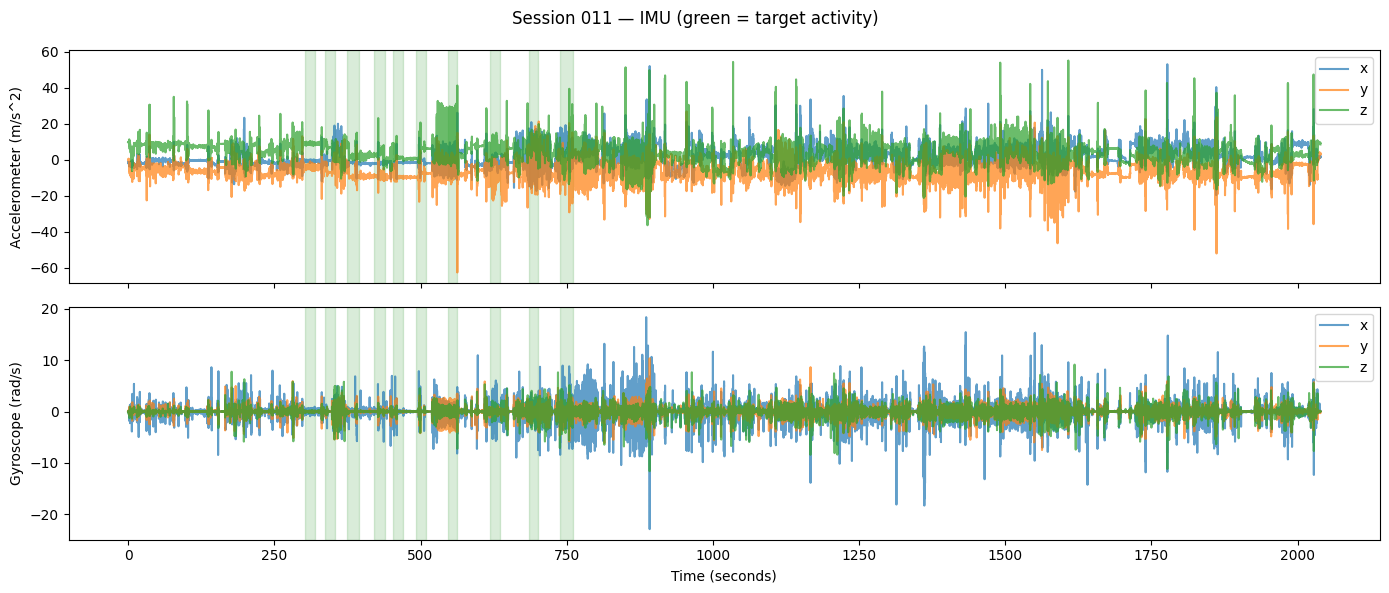

In [ ]:

# ============================================================
# DATA EXPLORATION
# ============================================================

# Load one example session
example = load_session(TRAIN_SESSIONS[0])

# Show annotation timeline
print("\nActivity timeline:")
for seg in example['annotations']:
    marker = ">>>" if seg['is_target'] else "   "
    print(f"  {marker} {seg['start_ms']/1000:7.1f}s - {seg['end_ms']/1000:7.1f}s  "
          f"({seg['duration_ms']/1000:.1f}s)  {seg['label']}")

# Plot IMU data with activity regions
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)

time_imu = np.arange(len(example['imu'])) / IMU_SAMPLE_RATE

axes[0].plot(time_imu, example['imu'][:, :3], alpha=0.7)
axes[0].set_ylabel('Accelerometer (m/s^2)')
axes[0].legend(['x', 'y', 'z'])

axes[1].plot(time_imu, example['imu'][:, 3:], alpha=0.7)
axes[1].set_ylabel('Gyroscope (rad/s)')
axes[1].set_xlabel('Time (seconds)')
axes[1].legend(['x', 'y', 'z'])

# Shade target activity regions
for seg in example['annotations']:
    if seg['is_target']:
        for ax in axes:
            ax.axvspan(seg['start_ms']/1000, seg['end_ms']/1000,
                      alpha=0.15, color='green')

plt.suptitle(f"Session {example['session_id']} — IMU (green = target activity)")
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# PREPROCESSING: 11 classes (10 targets + Other)
# ============================================================

WINDOW_SEC = 1.0
HOP_SEC = 0.5
N_MELS = 64
MEL_TIME_FRAMES = 96
MEL_HOP = 230
MEL_NFFT = 1024
CACHE_DIR = './preprocessed_cache_11class/'

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

os.makedirs(CACHE_DIR, exist_ok=True)


def get_window_label(start_ms, end_ms, annotations):
    """Assign label: target activity name, 'Other' (non-target activity or gap)."""
    best_overlap = 0
    best_label = 'Other'  # default: gap between activities
    for seg in annotations:
        overlap_start = max(start_ms, seg['start_ms'])
        overlap_end = min(end_ms, seg['end_ms'])
        overlap = max(0, overlap_end - overlap_start)
        if overlap > best_overlap:
            best_overlap = overlap
            # Target activities keep their name, non-target labeled as 'Other'
            best_label = seg['label'] if seg['label'] in TARGET_ACTIVITIES else 'Other'
    window_dur = end_ms - start_ms
    if best_overlap < window_dur * 0.5:
        return 'Other'
    return best_label


def preprocess_session(session_id, data_root=DATA_ROOT):
    """Extract windowed mel-spectrograms (64x96) and IMU features."""
    cache_path = os.path.join(CACHE_DIR, f'{session_id}.npz')
    if os.path.exists(cache_path):
        data = np.load(cache_path, allow_pickle=True)
        windows = data['windows'].tolist()
        print(f"  [{session_id}] {len(windows)} windows from cache")
        return windows

    import time
    t0 = time.time()
    session = load_session(session_id, data_root)
    imu = session['imu']
    audio = session['audio'].astype(np.float32)
    sr = session['sr']
    annotations = session['annotations']

    if audio.ndim == 2:  # Convert stereo to mono. If audio has: [left_channel, right_channel] average them.
        audio = audio.mean(axis=1)
    amax = np.abs(audio).max() # normalize the audio
    if amax > 0:
        audio = audio / amax

    full_mel = librosa.feature.melspectrogram( # Compute mel spectrogram. This converts: waveform → frequency representation over time.
        y=audio, sr=sr, n_mels=N_MELS, n_fft=MEL_NFFT, hop_length=MEL_HOP
    )
    full_mel_db = librosa.power_to_db(full_mel, ref=np.max).astype(np.float32)

    mel_frames_per_sec = sr / MEL_HOP
    imu_win = int(WINDOW_SEC * IMU_SAMPLE_RATE)
    imu_hop = int(HOP_SEC * IMU_SAMPLE_RATE)

    windows = []
    for i in range(0, len(imu) - imu_win + 1, imu_hop):
        t_start_ms = (i / IMU_SAMPLE_RATE) * 1000
        t_end_ms = ((i + imu_win) / IMU_SAMPLE_RATE) * 1000

        imu_window = imu[i:i + imu_win]
        if len(imu_window) < imu_win:
            continue

        mel_start = int(t_start_ms / 1000 * mel_frames_per_sec)
        mel_end = mel_start + MEL_TIME_FRAMES
        if mel_end > full_mel_db.shape[1]:
            continue
        mel_slice = full_mel_db[:, mel_start:mel_end]

        label = get_window_label(t_start_ms, t_end_ms, annotations)

        windows.append({
            'imu': imu_window.astype(np.float32),
            'mel': mel_slice,
            'label': label,
            'start_ms': t_start_ms,
            'end_ms': t_end_ms,
            'session_id': session_id
        })

    elapsed = time.time() - t0
    np.savez_compressed(cache_path, windows=np.array(windows, dtype=object))
    print(f"  [{session_id}] {len(windows)} windows in {elapsed:.1f}s -> cached")
    return windows


print("=== Preprocessing train sessions ===")
train_windows = []
for sid in TRAIN_SESSIONS:
    w = preprocess_session(sid)
    train_windows.extend(w)

from collections import Counter
label_dist = Counter(w['label'] for w in train_windows)
print(f"\nTotal: {len(train_windows)} windows")
for label in ALL_LABELS:
    print(f"  {label:15s}: {label_dist.get(label, 0)}")


Using device: cuda
=== Preprocessing train sessions ===
Loading session 011...
  [011] IMU: (101943, 6) (2038.9 sec)
  [011] Audio: (44334080, 2) samples, 22050 Hz (2010.6 sec)
  [011] Annotations: 22 total, 10 target activities
  [011] 4020 windows in 7.6s -> cached
Loading session 021...
  [021] IMU: (73898, 6) (1478.0 sec)
  [021] Audio: (32138240, 2) samples, 22050 Hz (1457.5 sec)
  [021] Annotations: 23 total, 10 target activities
  [021] 2914 windows in 1.1s -> cached
Loading session 031...
  [031] IMU: (87484, 6) (1749.7 sec)
  [031] Audio: (38044672, 2) samples, 22050 Hz (1725.4 sec)
  [031] Annotations: 23 total, 10 target activities
  [031] 3449 windows in 1.2s -> cached
Loading session 041...
  [041] IMU: (94938, 6) (1898.8 sec)
  [041] Audio: (41288704, 2) samples, 22050 Hz (1872.5 sec)
  [041] Annotations: 23 total, 10 target activities
  [041] 3744 windows in 1.4s -> cached
Loading session 051...
  [051] IMU: (89977, 6) (1799.5 sec)
  [051] Audio: (39131136, 2) samples, 2

In [ ]:

# ============================================================
# DATASET & DATALOADER (11 classes, no downsampling)
# ============================================================

class HARDataset(Dataset):
    """11-class dataset: 10 target activities + Other. No downsampling."""

    def __init__(self, windows):
        self.windows = windows

    def __len__(self):
        return len(self.windows)

    def __getitem__(self, idx):
        w = self.windows[idx]
        imu = torch.FloatTensor(w['imu'].T)
        mel = torch.FloatTensor(w['mel']).unsqueeze(0)
        label = ACTIVITY_TO_IDX[w['label']]
        return {
            'imu': imu, 'mel': mel, 'label': label,
            'start_ms': w['start_ms'], 'end_ms': w['end_ms'],
            'session_id': w['session_id']
        }


class HARDatasetAll(Dataset):
    def __init__(self, windows):
        self.windows = windows
    def __len__(self):
        return len(self.windows)
    def __getitem__(self, idx):
        w = self.windows[idx]
        return {
            'imu': torch.FloatTensor(w['imu'].T),
            'mel': torch.FloatTensor(w['mel']).unsqueeze(0),
            'start_ms': w['start_ms'], 'end_ms': w['end_ms'],
            'session_id': w['session_id']
        }


# Use ALL windows, no downsampling
train_dataset = HARDataset(train_windows)
print(f"Train dataset: {len(train_dataset)} windows (11 classes, full)")

label_counts = Counter(w['label'] for w in train_dataset.windows)
for label in ALL_LABELS:
    print(f"  {label:15s}: {label_counts.get(label, 0)}")

# Compute class weights for CrossEntropyLoss
n_samples = len(train_dataset)
class_weights = []
for label in ALL_LABELS:
    count = label_counts.get(label, 1)
    class_weights.append(n_samples / (NUM_CLASSES * count))
class_weights = torch.FloatTensor(class_weights)
print(f"\nClass weights:")
for label, w in zip(ALL_LABELS, class_weights):
    print(f"  {label:15s}: {w:.2f}")

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=0)


Train dataset: 28748 windows (11 classes, full)
  Scratching     : 493
  Wiping         : 499
  Hair           : 496
  Washing        : 505
  Drinking       : 532
  Eating         : 502
  Teeth          : 498
  Chopping       : 501
  Grating        : 481
  Frying         : 515
  Other          : 23726

Class weights:
  Scratching     : 5.30
  Wiping         : 5.24
  Hair           : 5.27
  Washing        : 5.18
  Drinking       : 4.91
  Eating         : 5.21
  Teeth          : 5.25
  Chopping       : 5.22
  Grating        : 5.43
  Frying         : 5.07
  Other          : 0.11


In [ ]:

# ============================================================
# MODEL DEFINITIONS (11 classes: 10 targets + Other)
# ============================================================


class AudioMobileNet(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES):
        super().__init__()
        import torchvision.models as models
        mn = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
        mn.features[0][0] = nn.Conv2d(1, 32, kernel_size=3, stride=2, padding=1, bias=False)
        self.features = mn.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(nn.Dropout(0.2), nn.Linear(1280, num_classes))

    def forward(self, mel):
        return self.classifier(self.pool(self.features(mel)).flatten(1))


class IMUCNN(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, in_channels=6):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(in_channels, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(128, 256, 3, padding=1), nn.BatchNorm1d(256), nn.ReLU(), nn.AdaptiveAvgPool1d(1),
        )
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, imu):
        return self.classifier(self.features(imu).squeeze(-1))


class LateFusionModel(nn.Module):
    def __init__(self, audio_model, imu_model):
        super().__init__()
        self.audio_model = audio_model
        self.imu_model = imu_model

    def forward(self, mel, imu):
        return (self.audio_model(mel) + self.imu_model(imu)) / 2.0


print(f"Models: {NUM_CLASSES}-class output (10 targets + Other)")

Models: 11-class output (10 targets + Other)


=== Training Audio-Only (MobileNetV2) ===
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 65.6MB/s]


Training (audio):   0%|          | 0/50 [00:00<?, ?it/s]

  Epoch  10: loss=0.4664, acc=0.623
  Epoch  20: loss=0.1895, acc=0.788
  Epoch  30: loss=0.0573, acc=0.913
  Epoch  40: loss=0.0195, acc=0.972
  Epoch  50: loss=0.0090, acc=0.986

=== Training IMU-Only (1D CNN) ===


Training (imu):   0%|          | 0/50 [00:00<?, ?it/s]

  Epoch  10: loss=1.0909, acc=0.343
  Epoch  20: loss=0.7116, acc=0.457
  Epoch  30: loss=0.4614, acc=0.556
  Epoch  40: loss=0.3473, acc=0.642
  Epoch  50: loss=0.2965, acc=0.680

=== Training Late Fusion ===


Training (fusion):   0%|          | 0/50 [00:00<?, ?it/s]

  Epoch  10: loss=0.3040, acc=0.716
  Epoch  20: loss=0.1281, acc=0.850
  Epoch  30: loss=0.0332, acc=0.949
  Epoch  40: loss=0.0111, acc=0.985
  Epoch  50: loss=0.0039, acc=0.995


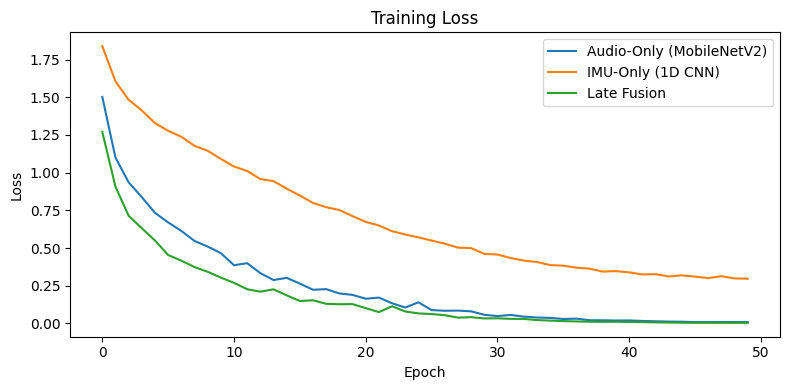

In [ ]:

# ============================================================
# TRAINING (with class weights)
# ============================================================

def train_model(model, train_loader, model_type='audio', epochs=50, lr=1e-3):
    """Train with class-weighted loss and cosine LR scheduling."""
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    criterion = nn.CrossEntropyLoss(weight=class_weights.to(device))
    losses = []

    for epoch in tqdm(range(epochs), desc=f'Training ({model_type})'):
        model.train()
        epoch_loss = 0
        correct = 0
        total = 0
        for batch in train_loader:
            mel = batch['mel'].to(device)
            imu = batch['imu'].to(device)
            labels = batch['label'].to(device)

            if model_type == 'audio':
                logits = model(mel)
            elif model_type == 'imu':
                logits = model(imu)
            else:
                logits = model(mel, imu)

            loss = criterion(logits, labels)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
            total += len(labels)

        scheduler.step()
        avg_loss = epoch_loss / total
        acc = correct / total
        losses.append(avg_loss)
        if (epoch + 1) % 10 == 0:
            tqdm.write(f"  Epoch {epoch+1:3d}: loss={avg_loss:.4f}, acc={acc:.3f}")

    return losses


# --- Train Audio-Only ---
print("=== Training Audio-Only (MobileNetV2) ===")
audio_model = AudioMobileNet()
audio_losses = train_model(audio_model, train_loader, model_type='audio', epochs=50, lr=1e-3)

# --- Train IMU-Only ---
print("\n=== Training IMU-Only (1D CNN) ===")
imu_model = IMUCNN()
imu_losses = train_model(imu_model, train_loader, model_type='imu', epochs=50, lr=1e-3)

# --- Train Fusion ---
print("\n=== Training Late Fusion ===")
fusion_audio = AudioMobileNet()
fusion_imu = IMUCNN()
fusion_model = LateFusionModel(fusion_audio, fusion_imu)
fusion_losses = train_model(fusion_model, train_loader, model_type='fusion', epochs=50, lr=1e-3)

# Plot training curves
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(audio_losses, label='Audio-Only (MobileNetV2)')
ax.plot(imu_losses, label='IMU-Only (1D CNN)')
ax.plot(fusion_losses, label='Late Fusion')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training Loss')
ax.legend()
plt.tight_layout()
plt.show()


In [ ]:

# ============================================================
# INFERENCE: 11-class model with temporal smoothing
# ============================================================

SMOOTH_WINDOW = 5  # median filter over 5 consecutive windows (~2.5s)


def run_inference(model, windows, model_type='audio'):
    """Run 11-class model on all windows."""
    dataset = HARDatasetAll(windows)
    loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=0)
    model.eval()
    model.to(device)

    all_preds = []
    all_probs = []
    all_meta = []

    with torch.no_grad():
        for batch in loader:
            mel = batch['mel'].to(device)
            imu = batch['imu'].to(device)

            if model_type == 'audio':
                logits = model(mel)
            elif model_type == 'imu':
                logits = model(imu)
            else:
                logits = model(mel, imu)

            probs = torch.softmax(logits, dim=1)
            preds = logits.argmax(dim=1)

            for i in range(len(preds)):
                all_preds.append(preds[i].item())
                all_probs.append(probs[i].cpu().numpy())
                all_meta.append({
                    'start_ms': batch['start_ms'][i].item(),
                    'end_ms': batch['end_ms'][i].item(),
                    'session_id': batch['session_id'][i]
                })

    return all_preds, all_probs, all_meta


def smooth_predictions(preds, meta, window=SMOOTH_WINDOW):
    """Apply temporal majority-vote smoothing per session.
    For each window, take the most common prediction among
    the surrounding `window` predictions."""
    from collections import defaultdict, Counter

    # Group by session
    session_indices = defaultdict(list)
    for i, m in enumerate(meta):
        session_indices[m['session_id']].append(i)

    smoothed = list(preds)  # copy
    for sid, indices in session_indices.items():
        indices.sort(key=lambda i: meta[i]['start_ms'])
        session_preds = [preds[i] for i in indices]
        half = window // 2
        for j, idx in enumerate(indices):
            start = max(0, j - half)
            end = min(len(session_preds), j + half + 1)
            neighborhood = session_preds[start:end]
            smoothed[idx] = Counter(neighborhood).most_common(1)[0][0]

    return smoothed


# --- Preprocess test sessions ---
print("=== Preprocessing test sessions ===")
test_windows = []
for sid in TEST_SESSIONS:
    w = preprocess_session(sid)
    test_windows.extend(w)
    print(f"  {sid}: {len(w)} windows")

# --- Run inference ---
print(f"\n=== Running inference (11-class, smoothing={SMOOTH_WINDOW} windows) ===")
print("Audio-only...")
audio_preds_raw, audio_probs, audio_meta = run_inference(audio_model, test_windows, 'audio')
audio_preds = smooth_predictions(audio_preds_raw, audio_meta)

print("IMU-only...")
imu_preds_raw, imu_probs, imu_meta = run_inference(imu_model, test_windows, 'imu')
imu_preds = smooth_predictions(imu_preds_raw, imu_meta)

print("Fusion...")
fusion_preds_raw, fusion_probs, fusion_meta = run_inference(fusion_model, test_windows, 'fusion')
fusion_preds = smooth_predictions(fusion_preds_raw, fusion_meta)

print("\nPredictions ready!")
for sid in TEST_SESSIONS:
    n_other = sum(1 for p, m in zip(audio_preds, audio_meta) if m['session_id'] == sid and p == OTHER_IDX)
    n_total = sum(1 for m in audio_meta if m['session_id'] == sid)
    print(f"  {sid}: audio Other={n_other}/{n_total} ({100*n_other/n_total:.0f}%)")


=== Preprocessing test sessions ===
Loading session 111...
  [111] IMU: (100807, 6) (2016.1 sec)
  [111] Audio: (43840512, 2) samples, 22050 Hz (1988.2 sec)
  [111] Annotations: 23 total, 10 target activities
  [111] 3975 windows in 1.5s -> cached
  111: 3975 windows
Loading session 121...
  [121] IMU: (89006, 6) (1780.1 sec)
  [121] Audio: (38709248, 2) samples, 22050 Hz (1755.5 sec)
  [121] Annotations: 23 total, 10 target activities
  [121] 3510 windows in 1.3s -> cached
  121: 3510 windows
Loading session 131...
  [131] IMU: (90550, 6) (1811.0 sec)
  [131] Audio: (39380992, 2) samples, 22050 Hz (1786.0 sec)
  [131] Annotations: 23 total, 10 target activities
  [131] 3570 windows in 1.3s -> cached
  131: 3570 windows
Loading session 141...
  [141] IMU: (93054, 6) (1861.1 sec)
  [141] Audio: (40471552, 2) samples, 22050 Hz (1835.4 sec)
  [141] Annotations: 23 total, 10 target activities
  [141] 3669 windows in 1.3s -> cached
  141: 3669 windows
Loading session 151...
  [151] IMU: (10

In [ ]:

# ============================================================
# RF BINARY DETECTOR (SAMoSA-style)
# ============================================================
from sklearn.ensemble import RandomForestClassifier
from scipy.stats import skew, kurtosis

def extract_imu_features(imu_window):
    """SAMoSA-style hand-crafted features per IMU window.
    Input: (50, 6) -> Output: (48,) feature vector."""
    feats = np.hstack([
        imu_window.mean(axis=0),     # 6
        imu_window.std(axis=0),      # 6
        imu_window.max(axis=0),      # 6
        imu_window.min(axis=0),      # 6
        np.median(imu_window, axis=0),  # 6
        imu_window.var(axis=0),      # 6
        skew(imu_window, axis=0),    # 6
        kurtosis(imu_window, axis=0) # 6
    ])
    return feats  # 48 features


# Extract features and binary labels for training
print("=== Training RF Binary Detector (SAMoSA-style) ===")
X_rf = np.array([extract_imu_features(w['imu']) for w in train_dataset.windows])
y_rf = np.array(['Activity' if w['label'] != 'Other' else 'Other'
                  for w in train_dataset.windows])

print(f"  RF training: {X_rf.shape[0]} samples, {X_rf.shape[1]} features")
print(f"  Activity: {(y_rf=='Activity').sum()}, Other: {(y_rf=='Other').sum()}")

# Normalize (SAMoSA-style: percentile + standardize)
pseudo_max = np.percentile(X_rf, 80, axis=0, keepdims=True)
pseudo_min = np.percentile(X_rf, 20, axis=0, keepdims=True)
mean_rf = X_rf.mean(axis=0, keepdims=True)
std_rf = X_rf.std(axis=0, keepdims=True) + 1e-8

X_rf_norm = 1 + (X_rf - pseudo_max) * 2 / (pseudo_max - pseudo_min + 1e-8)
X_rf_norm = (X_rf_norm - mean_rf) / std_rf

# Train RF
rf_detector = RandomForestClassifier(
    n_estimators=100, max_depth=10, class_weight='balanced',
    random_state=42, n_jobs=-1
)
rf_detector.fit(X_rf_norm, y_rf)

# Train accuracy
train_pred = rf_detector.predict(X_rf_norm)
from sklearn.metrics import balanced_accuracy_score
train_ba = balanced_accuracy_score(y_rf, train_pred)
train_f1 = f1_score(y_rf, train_pred, pos_label='Activity')
print(f"  Train BA: {train_ba:.3f}, F1: {train_f1:.3f}")


=== Training RF Binary Detector (SAMoSA-style) ===
  RF training: 28748 samples, 48 features
  Activity: 5022, Other: 23726
  Train BA: 0.822, F1: 0.657


In [ ]:

# ============================================================
# INFERENCE: DL models for classification + RF for detection
# ============================================================

def run_rf_detection(windows):
    """Run RF binary detector on all windows using IMU features."""
    X_test_rf = np.array([extract_imu_features(w['imu']) for w in windows])
    X_test_norm = 1 + (X_test_rf - pseudo_max) * 2 / (pseudo_max - pseudo_min + 1e-8)
    X_test_norm = (X_test_norm - mean_rf) / std_rf

    rf_preds = rf_detector.predict(X_test_norm)
    rf_preds_int = [0 if p == 'Activity' else OTHER_IDX for p in rf_preds]

    meta = [{'start_ms': w['start_ms'], 'end_ms': w['end_ms'], 'session_id': w['session_id']}
            for w in windows]

    return rf_preds_int, meta


# --- RF detection on test data ---
print("RF binary detection on test data...")
rf_det_preds_raw, rf_det_meta = run_rf_detection(test_windows)
rf_det_preds = smooth_predictions(rf_det_preds_raw, rf_det_meta)
print(f"Done. {sum(1 for p in rf_det_preds if p != OTHER_IDX)}/{len(rf_det_preds)} windows predicted as Activity")


RF binary detection on test data...
Done. 3140/19002 windows predicted as Activity


---
## Evaluation and Analysis

Models are evaluated on all **five held-out test sessions**. Detection and classification are reported separately.

### Activity Detection

Window-level detection distinguishes Activity from Other within the block between each session's first and last target activity. Segment-level detection uses majority voting within annotated intervals.

**Metrics:** binary F1, balanced accuracy, precision, recall, mean onset delay, and mean offset delay.

### Activity Classification

Window-level classification evaluates windows overlapping target activities. Known-segment classification sums window probabilities within each ground-truth target segment and selects among the ten target classes, excluding Other.

**Metrics:** macro F1, per-class F1, and confusion matrices.

A known-segment classification score assumes activity boundaries are available; it is not continuous-stream recognition accuracy. Centered prediction smoothing uses future windows and is intended for offline analysis.


### Prediction Format

Evaluation consumes window predictions, class probabilities, and metadata containing each window's session ID, start time, and end time.


In [ ]:

# ============================================================
# EVAL 1: DETECTION + FRAME-LEVEL CLASSIFICATION
# ============================================================

def evaluate_detection_framelevel(preds, meta, test_sessions=TEST_SESSIONS):
    """Frame-level activity detection eval (binary: Activity vs Other).
    Only within the target activity block."""
    from sklearn.metrics import precision_score, recall_score, balanced_accuracy_score

    gt_cache = {}
    for sid in test_sessions:
        gt_cache[sid] = load_gt_segments(sid)

    gt_labels_binary = []
    pred_labels_binary = []
    n_skipped = 0

    for pred, m in zip(preds, meta):
        sid = m['session_id']
        gt_segs = gt_cache[sid]
        block_start = min(gs['start_ms'] for gs in gt_segs)
        block_end = max(gs['end_ms'] for gs in gt_segs)

        if m['end_ms'] <= block_start or m['start_ms'] >= block_end:
            n_skipped += 1
            continue

        is_target = False
        for gs in gt_segs:
            overlap = max(0, min(m['end_ms'], gs['end_ms']) - max(m['start_ms'], gs['start_ms']))
            if overlap >= (m['end_ms'] - m['start_ms']) * 0.5:
                is_target = True
                break

        gt_labels_binary.append('Activity' if is_target else 'Other')
        pred_labels_binary.append('Activity' if pred != OTHER_IDX else 'Other')

    binary_f1 = f1_score(gt_labels_binary, pred_labels_binary, pos_label='Activity')
    binary_prec = precision_score(gt_labels_binary, pred_labels_binary, pos_label='Activity')
    binary_rec = recall_score(gt_labels_binary, pred_labels_binary, pos_label='Activity')
    binary_ba = balanced_accuracy_score(gt_labels_binary, pred_labels_binary)

    n_activity = sum(1 for l in gt_labels_binary if l == 'Activity')
    n_other = sum(1 for l in gt_labels_binary if l == 'Other')

    # Onset / Offset delays
    onset_delays = []
    offset_delays = []
    for sid in test_sessions:
        gt_segs = gt_cache[sid]
        sid_data = [(p, m) for p, m in zip(preds, meta) if m['session_id'] == sid]
        sid_data.sort(key=lambda x: x[1]['start_ms'])
        for gs in gt_segs:
            found = False
            for p, m in sid_data:
                if m['start_ms'] >= gs['start_ms'] and m['end_ms'] <= gs['end_ms']:
                    if p != OTHER_IDX:
                        onset_delays.append((m['start_ms'] - gs['start_ms']) / 1000.0)
                        found = True
                        break
            if not found:
                onset_delays.append(np.nan)
            found = False
            for p, m in sid_data:
                if m['start_ms'] >= gs['end_ms']:
                    if p == OTHER_IDX:
                        offset_delays.append((m['start_ms'] - gs['end_ms']) / 1000.0)
                        found = True
                        break
            if not found:
                offset_delays.append(np.nan)

    n_detected = sum(1 for d in onset_delays if not np.isnan(d))
    n_total = len(onset_delays)
    mean_onset = np.nanmean(onset_delays) if n_detected > 0 else float('inf')
    mean_offset = np.nanmean(offset_delays)

    results = {
        'binary_f1': binary_f1, 'binary_precision': binary_prec,
        'binary_recall': binary_rec, 'balanced_accuracy': binary_ba,
        'mean_onset_delay_sec': mean_onset, 'mean_offset_delay_sec': mean_offset,
        'detection_rate': n_detected / n_total
    }

    print(f"  [Frame detection] F1={binary_f1:.4f}  BA={binary_ba:.4f}  P={binary_prec:.4f}  R={binary_rec:.4f}")
    print(f"    {len(gt_labels_binary)} windows ({n_activity} Act, {n_other} Other), skipped {n_skipped}")
    print(f"    Detection: {n_detected}/{n_total} ({100*n_detected/n_total:.0f}%)  Onset={mean_onset:.2f}s  Offset={mean_offset:.2f}s")
    return results


def evaluate_classification_framelevel(preds, meta, test_sessions=TEST_SESSIONS):
    """Frame-level 11-class classification eval.
    Only on windows that overlap with a target activity segment.
    Each window gets a GT label from its overlapping target activity."""

    gt_cache = {}
    for sid in test_sessions:
        gt_cache[sid] = load_gt_segments(sid)

    gt_labels = []
    pred_labels = []

    for pred, m in zip(preds, meta):
        sid = m['session_id']
        gt_segs = gt_cache[sid]

        # Find which target activity this window belongs to
        best_label = None
        best_overlap = 0
        for gs in gt_segs:
            overlap = max(0, min(m['end_ms'], gs['end_ms']) - max(m['start_ms'], gs['start_ms']))
            if overlap > best_overlap:
                best_overlap = overlap
                best_label = gs['label']

        # Only eval on windows inside target activities (>50% overlap)
        if best_label is None or best_overlap < (m['end_ms'] - m['start_ms']) * 0.5:
            continue

        gt_labels.append(best_label)
        pred_label = IDX_TO_ACTIVITY.get(pred, 'Other')
        pred_labels.append(pred_label)

    macro_f1 = f1_score(gt_labels, pred_labels, labels=TARGET_ACTIVITIES,
                        average='macro', zero_division=0)
    per_class = f1_score(gt_labels, pred_labels, labels=TARGET_ACTIVITIES,
                         average=None, zero_division=0)

    print(f"  [Frame classification] Macro F1={macro_f1:.4f}  ({len(gt_labels)} activity windows)")
    for act, f in zip(TARGET_ACTIVITIES, per_class):
        print(f"    {act:15s}: {f:.4f}")

    return {'frame_class_f1': macro_f1,
            'frame_per_class': dict(zip(TARGET_ACTIVITIES, per_class.tolist()))}


def evaluate_detection_majority_vote(preds, probs, meta, test_sessions=TEST_SESSIONS):
    """Per-segment majority vote detection eval."""
    from sklearn.metrics import balanced_accuracy_score

    gt_all_binary = []
    pred_all_binary = []

    for sid in test_sessions:
        session_dir = _get_session_dir(sid)
        df = pd.read_csv(os.path.join(session_dir, f'{sid}ant.csv'), sep='\t')
        sid_data = [(p, m) for p, m in zip(preds, meta) if m['session_id'] == sid]

        for _, row in df.iterrows():
            label = str(row['Label']).strip()
            seg_start = float(row['Start (ms)'])
            seg_end = float(row['End (ms)'])
            is_target = label in TARGET_ACTIVITIES

            n_activity = 0
            n_other = 0
            for p, m in sid_data:
                overlap = max(0, min(m['end_ms'], seg_end) - max(m['start_ms'], seg_start))
                if overlap >= (m['end_ms'] - m['start_ms']) * 0.5:
                    if p != OTHER_IDX:
                        n_activity += 1
                    else:
                        n_other += 1

            if n_activity + n_other == 0:
                continue

            gt_all_binary.append('Activity' if is_target else 'Other')
            pred_all_binary.append('Activity' if n_activity > n_other else 'Other')

    mv_f1 = f1_score(gt_all_binary, pred_all_binary, pos_label='Activity')
    mv_ba = balanced_accuracy_score(gt_all_binary, pred_all_binary)

    n_act = sum(1 for l in gt_all_binary if l == 'Activity')
    n_oth = sum(1 for l in gt_all_binary if l == 'Other')

    print(f"  [Majority vote detection] F1={mv_f1:.4f}  BA={mv_ba:.4f}  ({n_act} Act, {n_oth} Other segments)")
    return {'mv_f1': mv_f1, 'mv_ba': mv_ba}


In [ ]:
# Run all evaluations
for name, preds, probs, meta in [
    ("RF Detector", rf_det_preds, None, rf_det_meta),
    ("Audio DL", audio_preds, audio_probs, audio_meta),
    ("IMU DL", imu_preds, imu_probs, imu_meta),
    ("Fusion DL", fusion_preds, fusion_probs, fusion_meta),
]:
    print(f"\n{'='*50}")
    print(f"  {name}")
    print(f"{'='*50}")
    det_frame = evaluate_detection_framelevel(preds, meta)
    det_mv = evaluate_detection_majority_vote(preds, probs, meta)
    if name != "RF Detector":
        cls_frame = evaluate_classification_framelevel(preds, meta)
    else:
        cls_frame = {'frame_class_f1': '-', 'frame_per_class': {}}

    if name == "RF Detector":
        det_results_rf = {**det_frame, **det_mv, **cls_frame}
    elif name == "Audio DL":
        det_results_audio = {**det_frame, **det_mv, **cls_frame}
    elif name == "IMU DL":
        det_results_imu = {**det_frame, **det_mv, **cls_frame}
    elif name == "Fusion DL":
        det_results_fusion = {**det_frame, **det_mv, **cls_frame}


  RF Detector
  [Frame detection] F1=0.5092  BA=0.6206  P=0.5831  R=0.4520
    8410 windows (3321 Act, 5089 Other), skipped 10592
    Detection: 46/50 (92%)  Onset=10.55s  Offset=5.41s
  [Majority vote detection] F1=0.6667  BA=0.7500  (50 Act, 65 Other segments)

  Audio DL
  [Frame detection] F1=0.3858  BA=0.6144  P=0.9094  R=0.2448
    8410 windows (3321 Act, 5089 Other), skipped 10592
    Detection: 36/50 (72%)  Onset=5.36s  Offset=0.26s
  [Majority vote detection] F1=0.3871  BA=0.6200  (50 Act, 65 Other segments)
  [Frame classification] Macro F1=0.3406  (3321 activity windows)
    Scratching     : 0.0580
    Wiping         : 0.3136
    Hair           : 0.0348
    Washing        : 0.6017
    Drinking       : 0.1432
    Eating         : 0.0997
    Teeth          : 0.5957
    Chopping       : 0.6021
    Grating        : 0.7036
    Frying         : 0.2538

  IMU DL
  [Frame detection] F1=0.5252  BA=0.5876  P=0.4845  R=0.5733
    8410 windows (3321 Act, 5089 Other), skipped 10592
    

In [ ]:
# ============================================================
# EVAL 2: ACTIVITY CLASSIFICATION (10-class, target segments only)
# ============================================================

def evaluate_classification_segment(preds, probs, meta, test_sessions=TEST_SESSIONS):
    """Per-segment 10-class classification.
    Only evaluates on target activity segments.
    For each target segment, sum window probabilities and pick argmax among 10 classes."""

    gt_labels = []
    pred_labels = []

    for sid in test_sessions:
        gt_segs = load_gt_segments(sid)
        sid_data = [(p, pr, m) for p, pr, m in zip(preds, probs, meta)
                    if m['session_id'] == sid]

        for gs in gt_segs:
            sum_probs = np.zeros(NUM_CLASSES)
            count = 0
            for p, pr, m in sid_data:
                overlap = max(0, min(m['end_ms'], gs['end_ms']) - max(m['start_ms'], gs['start_ms']))
                if overlap > 0:
                    sum_probs += pr
                    count += 1

            if count > 0:
                # Pick argmax among 10 target classes only (exclude Other)
                target_probs = sum_probs[:len(TARGET_ACTIVITIES)]
                pred_idx = np.argmax(target_probs)
                pred_labels.append(TARGET_ACTIVITIES[pred_idx])
            else:
                pred_labels.append(TARGET_ACTIVITIES[0])

            gt_labels.append(gs['label'])

    macro_f1 = f1_score(gt_labels, pred_labels, labels=TARGET_ACTIVITIES,
                        average='macro', zero_division=0)
    per_class_f1 = f1_score(gt_labels, pred_labels, labels=TARGET_ACTIVITIES,
                            average=None, zero_division=0)
    cm = confusion_matrix(gt_labels, pred_labels, labels=TARGET_ACTIVITIES)

    print(f"  Segment classification ({len(gt_labels)} target segments)")
    print(f"  Macro F1: {macro_f1:.4f}")
    print(f"  Per-class F1:")
    for act, f in zip(TARGET_ACTIVITIES, per_class_f1):
        print(f"    {act:15s}: {f:.4f}")

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=TARGET_ACTIVITIES, yticklabels=TARGET_ACTIVITIES, ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Ground Truth')
    ax.set_title('Classification Confusion Matrix (10-class)')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return {'seg_f1': macro_f1,
            'seg_per_class': dict(zip(TARGET_ACTIVITIES, per_class_f1.tolist()))}

--- Audio-Only Classification ---
  Segment classification (50 target segments)
  Macro F1: 0.7771
  Per-class F1:
    Scratching     : 0.6667
    Wiping         : 0.6000
    Hair           : 0.5000
    Washing        : 0.9091
    Drinking       : 0.7500
    Eating         : 0.7692
    Teeth          : 0.8889
    Chopping       : 0.8889
    Grating        : 0.9091
    Frying         : 0.8889


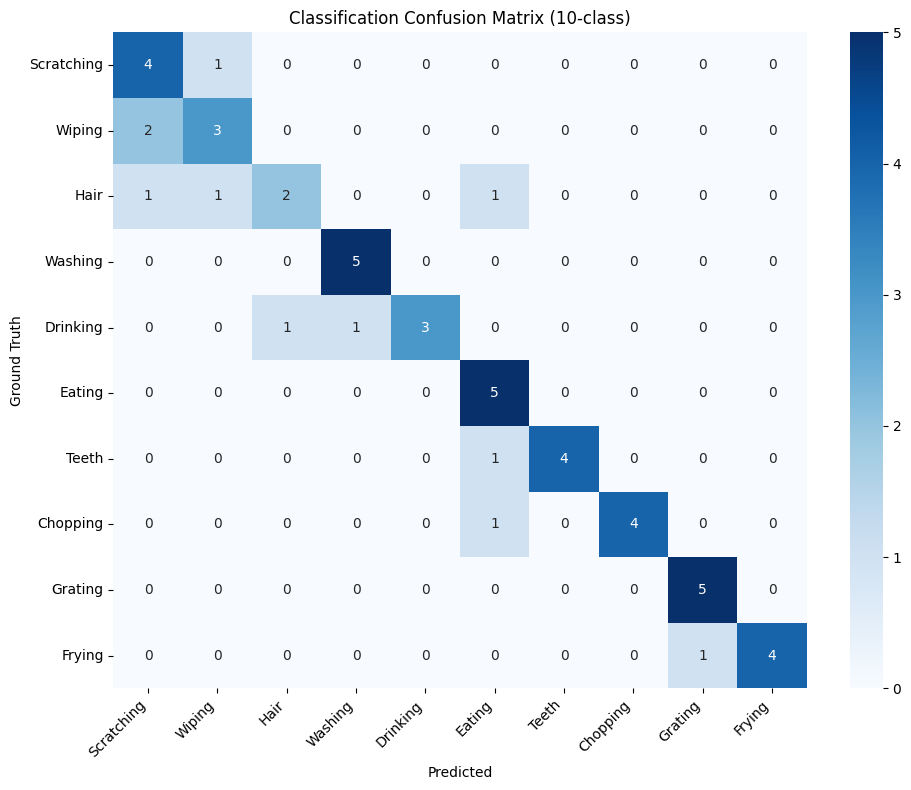


--- IMU-Only Classification ---
  Segment classification (50 target segments)
  Macro F1: 0.7631
  Per-class F1:
    Scratching     : 0.7273
    Wiping         : 0.8889
    Hair           : 0.8000
    Washing        : 0.8333
    Drinking       : 0.8333
    Eating         : 0.7500
    Teeth          : 0.8889
    Chopping       : 0.9091
    Grating        : 0.3333
    Frying         : 0.6667


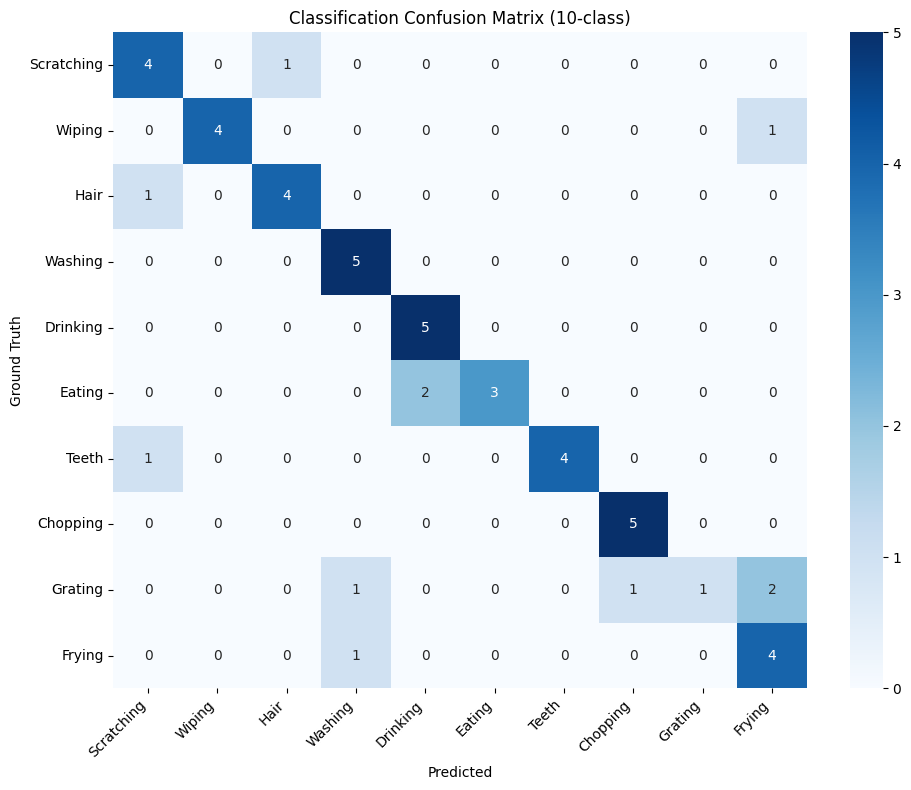


--- Multimodal Fusion Classification ---
  Segment classification (50 target segments)
  Macro F1: 0.8614
  Per-class F1:
    Scratching     : 0.8000
    Wiping         : 0.7273
    Hair           : 0.6000
    Washing        : 0.9091
    Drinking       : 0.8000
    Eating         : 0.8889
    Teeth          : 1.0000
    Chopping       : 1.0000
    Grating        : 1.0000
    Frying         : 0.8889


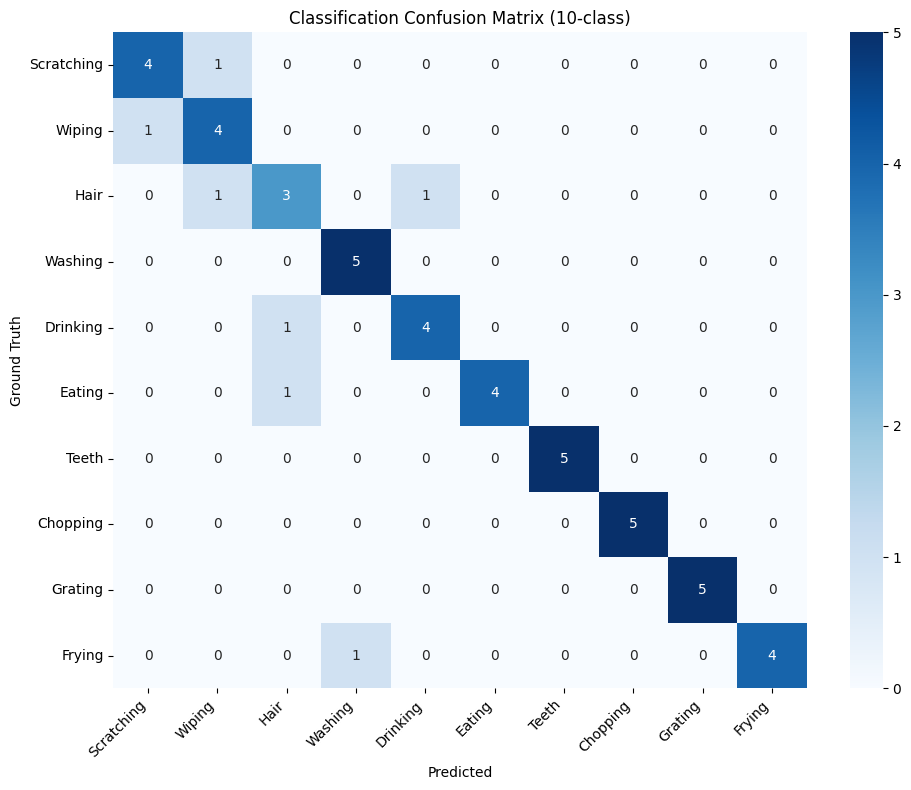

In [ ]:
# Run classification evaluation for all 3 DL models (11-class: 10 targets + Other)
print("--- Audio-Only Classification ---")
cls_results_audio = evaluate_classification_segment(audio_preds, audio_probs, audio_meta)
print()
print("--- IMU-Only Classification ---")
cls_results_imu = evaluate_classification_segment(imu_preds, imu_probs, imu_meta)
print()
print("--- Multimodal Fusion Classification ---")
cls_results_fusion = evaluate_classification_segment(fusion_preds, fusion_probs, fusion_meta)

Using device: cuda
Starting Two-Stage Training...
>>> Stage 1: Training Attention Layers Only (CNNs Frozen)
Epoch [1/50] Train Loss: 0.7961 | Train Acc: 0.8235
Epoch [2/50] Train Loss: 0.6632 | Train Acc: 0.8331
Epoch [3/50] Train Loss: 0.6194 | Train Acc: 0.8393
Epoch [4/50] Train Loss: 0.5919 | Train Acc: 0.8429
Epoch [5/50] Train Loss: 0.5658 | Train Acc: 0.8469
Epoch [6/50] Train Loss: 0.5456 | Train Acc: 0.8508
Epoch [7/50] Train Loss: 0.5293 | Train Acc: 0.8541
Epoch [8/50] Train Loss: 0.5094 | Train Acc: 0.8592
Epoch [9/50] Train Loss: 0.4952 | Train Acc: 0.8616
Epoch [10/50] Train Loss: 0.4831 | Train Acc: 0.8648
Epoch [11/50] Train Loss: 0.4691 | Train Acc: 0.8685
Epoch [12/50] Train Loss: 0.4605 | Train Acc: 0.8682
Epoch [13/50] Train Loss: 0.4494 | Train Acc: 0.8712
Epoch [14/50] Train Loss: 0.4391 | Train Acc: 0.8736
Epoch [15/50] Train Loss: 0.4306 | Train Acc: 0.8753
>>> Stage 2: Fine-Tuning Entire Network (CNNs Unfrozen)
Epoch [16/50] Train Loss: 0.4347 | Train Acc: 0.87

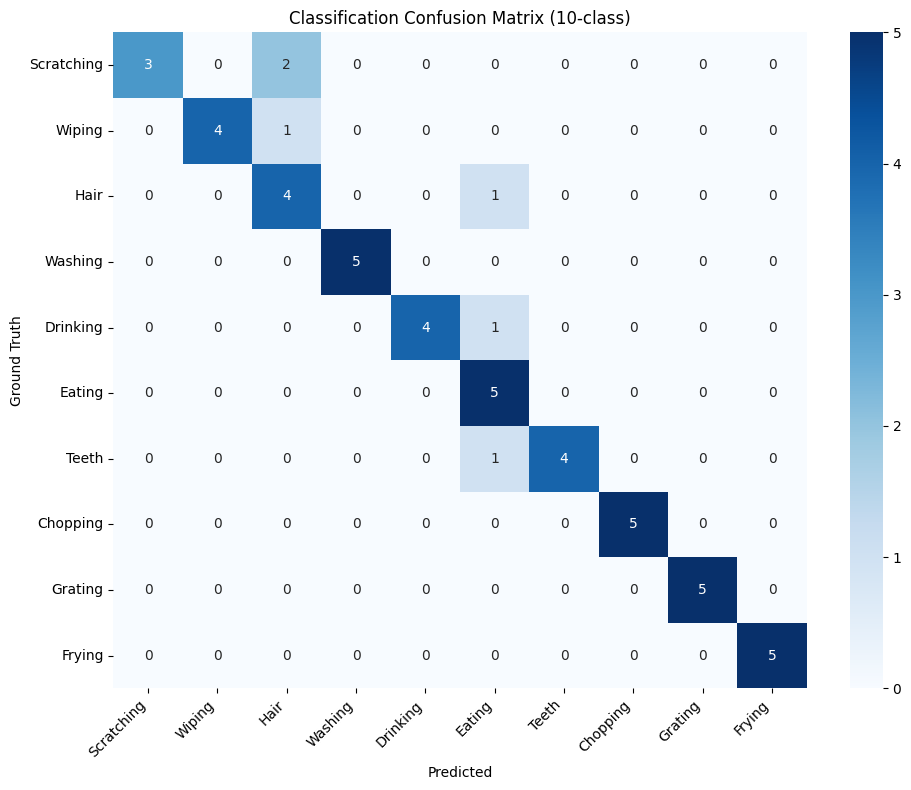

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import math
from scipy.signal import medfilt

# ==========================================
# 1. NEW COMPONENTS: POSITIONAL ENCODING & POOLING
# ==========================================
class PositionalEncoding(nn.Module):
    """Injects temporal awareness into the sequence before attention."""
    def __init__(self, d_model, max_len=5000):
        super(PositionalEncoding, self).__init__()
        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0) # Shape: (1, max_len, d_model)
        self.register_buffer('pe', pe)

    def forward(self, x):
        # x shape expected: (Batch, SeqLen, d_model)
        x = x + self.pe[:, :x.size(1), :]
        return x

class AttentionPooling(nn.Module):
    """Learns which specific time-steps in the window are the most important."""
    def __init__(self, embed_dim):
        super(AttentionPooling, self).__init__()
        self.attention_weights = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.Tanh(),
            nn.Linear(128, 1),
            nn.Softmax(dim=1) # Softmax across the sequence length
        )

    def forward(self, x):
        # x shape: (Batch, SeqLen, embed_dim)
        weights = self.attention_weights(x)         # (Batch, SeqLen, 1)
        pooled = torch.sum(x * weights, dim=1)      # Weighted sum -> (Batch, embed_dim)
        return pooled

# ==========================================
# 2. UNIMODAL FEATURE EXTRACTORS
# ==========================================
class IMUFeatureExtractor(nn.Module):
    def __init__(self, in_channels=6, out_dim=128):
        super(IMUFeatureExtractor, self).__init__()
        self.conv_blocks = nn.Sequential(
            nn.Conv1d(in_channels, 64, kernel_size=5, padding=2),
            nn.ReLU(),
            nn.MaxPool1d(2),
            nn.Conv1d(64, out_dim, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool1d(2)
        )

    def forward(self, x):
        features = self.conv_blocks(x)
        return features.transpose(1, 2) # (Batch, SeqLen, Features)

class AudioFeatureExtractor(nn.Module):
    def __init__(self, in_channels=1, out_dim=64):
        super(AudioFeatureExtractor, self).__init__()
        # Input shape: [Batch, 1, Freq_Bands, Time_Frames]
        self.conv_blocks = nn.Sequential(
            nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)), # Reduces Freq and Time by half

            nn.Conv2d(32, out_dim, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_dim),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 2)), # Reduces Freq and Time by half again
        )

        # This brilliantly averages out the remaining frequency dimension
        # but leaves the Time dimension perfectly intact for our attention layers!
        self.freq_pool = nn.AdaptiveAvgPool2d((1, None))

    def forward(self, x):
        # x is [B, 1, 64, 96]
        features = self.conv_blocks(x)            # Turns into [B, 64, 16, 24]
        features = self.freq_pool(features)       # Turns into [B, 64, 1, 24]
        features = features.squeeze(2)            # Removes the '1' dim -> [B, 64, 24]

        # Swap axes to match Cross-Attention requirements: (Batch, SeqLen, Features)
        return features.transpose(1, 2)           # Final shape: [B, 24, 64]

# ==========================================
# 3. CORRECTED CROSS-ATTENTION FUSION MODEL
# ==========================================
class CrossAttentionFusionHAR(nn.Module):
    def __init__(self, audio_ext, imu_ext, audio_dim=64, imu_dim=128, embed_dim=128, num_heads=4, num_classes=11, dropout=0.3):
        super(CrossAttentionFusionHAR, self).__init__()

        self.audio_extractor = audio_ext
        self.imu_extractor = imu_ext

        # 1. Projections & Positional Encoding
        self.audio_proj = nn.Linear(audio_dim, embed_dim)
        self.imu_proj = nn.Linear(imu_dim, embed_dim)
        self.pos_encoder = PositionalEncoding(embed_dim)

        # 2. Cross-Attention Layers
        self.cross_attn_a_queries_i = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)
        self.cross_attn_i_queries_a = nn.MultiheadAttention(embed_dim, num_heads, dropout=dropout, batch_first=True)

        # 3. Layer Normalization
        self.norm_a = nn.LayerNorm(embed_dim)
        self.norm_i = nn.LayerNorm(embed_dim)

        # 4. Attention Pooling (Replaces torch.mean)
        self.audio_pooler = AttentionPooling(embed_dim)
        self.imu_pooler = AttentionPooling(embed_dim)

        # 5. Final Classification Head
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim * 2, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )

    def forward(self, audio_x, imu_x):
        # Extract sequences
        audio_seq = self.audio_extractor(audio_x)
        imu_seq = self.imu_extractor(imu_x)

        # Project and add Time (Positional Encoding)
        a_emb = self.pos_encoder(self.audio_proj(audio_seq))
        i_emb = self.pos_encoder(self.imu_proj(imu_seq))

        # Cross-Attention
        attn_out_a, _ = self.cross_attn_a_queries_i(query=a_emb, key=i_emb, value=i_emb)
        attn_out_i, _ = self.cross_attn_i_queries_a(query=i_emb, key=a_emb, value=a_emb)

        # Residual + Norm
        a_fused = self.norm_a(a_emb + attn_out_a)
        i_fused = self.norm_i(i_emb + attn_out_i)

        # Smart Temporal Pooling
        a_pooled = self.audio_pooler(a_fused)
        i_pooled = self.imu_pooler(i_fused)

        # Concatenate and Classify
        fused_vector = torch.cat([a_pooled, i_pooled], dim=1)
        logits = self.classifier(fused_vector)
        return logits

    def set_extractor_gradients(self, requires_grad=True):
        """Helper to freeze/unfreeze CNNs for two-stage training."""
        for param in self.audio_extractor.parameters():
            param.requires_grad = requires_grad
        for param in self.imu_extractor.parameters():
            param.requires_grad = requires_grad

# ==========================================
# 4. TWO-STAGE TRAINING LOOP
# ==========================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Initialize Model
audio_ext = AudioFeatureExtractor(in_channels=1, out_dim=64)
imu_ext = IMUFeatureExtractor(in_channels=6, out_dim=128)

# (Optional but recommended): Load your pre-trained weights here before fusing!
# audio_ext.load_state_dict(torch.load('audio_best.pth'))
# imu_ext.load_state_dict(torch.load('imu_best.pth'))

model = CrossAttentionFusionHAR(audio_ext, imu_ext, num_classes=11).to(device)

criterion = nn.CrossEntropyLoss()
# Separate optimizer so we can control learning rates later if needed
optimizer = optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)

num_epochs = 50
warmup_epochs = 15 # Number of epochs to freeze CNNs and only train Attention

print("Starting Two-Stage Training...")

for epoch in range(num_epochs):

    # --- The "Cold Start" Fix ---
    if epoch < warmup_epochs:
        model.set_extractor_gradients(requires_grad=False)
        if epoch == 0: print(">>> Stage 1: Training Attention Layers Only (CNNs Frozen)")
    else:
        model.set_extractor_gradients(requires_grad=True)
        if epoch == warmup_epochs: print(">>> Stage 2: Fine-Tuning Entire Network (CNNs Unfrozen)")

    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for batch in train_loader:
        audio = batch['mel'].to(device)
        imu = batch['imu'].to(device)
        labels = batch['label'].to(device)

        optimizer.zero_grad()
        logits = model(audio, imu)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * labels.size(0)
        _, preds = torch.max(logits, 1)
        correct += torch.sum(preds == labels.data).item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_acc = correct / total

    print(f"Epoch [{epoch+1}/{num_epochs}] Train Loss: {epoch_loss:.4f} | Train Acc: {epoch_acc:.4f}")

print("Training Complete!")

# ==========================================
# 5. EVALUATION LOOP
# ==========================================
test_loader = DataLoader(HARDatasetAll(test_windows), batch_size=64, shuffle=False, num_workers=0)
model.eval()
fusion_preds, fusion_probs, fusion_meta = [], [], []

print("Running Inference on Test Set...")
with torch.no_grad():
    for batch in test_loader:
        # 1. Grab the sensor data
        audio = batch['mel'].to(device)
        imu = batch['imu'].to(device)

        # 2. Grab the flattened metadata directly from the batch
        session_ids = batch['session_id']
        starts = batch['start_ms']
        ends = batch['end_ms']

        # 3. Forward pass
        logits = model(audio, imu)
        probs = F.softmax(logits, dim=1)
        preds = torch.argmax(probs, dim=1)

        # 4. Store predictions
        fusion_preds.extend(preds.cpu().numpy().tolist())
        fusion_probs.extend(probs.cpu().numpy().tolist())

        # 5. Reconstruct the metadata dictionary
        for i in range(len(preds)):
            fusion_meta.append({
                'session_id': session_ids[i],
                'start_ms': starts[i].item(),
                'end_ms': ends[i].item()
            })

# ==========================================
# 6. FINAL METRICS OUTPUT
# ==========================================
print("\n=== Smoothed Cross-Attention Fusion Evaluation ===")
det_frame = evaluate_detection_framelevel(fusion_preds, fusion_meta)
det_mv = evaluate_detection_majority_vote(fusion_preds, fusion_probs, fusion_meta)
cls_frame = evaluate_classification_framelevel(fusion_preds, fusion_meta)
cls_seg = evaluate_classification_segment(fusion_preds, fusion_probs, fusion_meta)

## Results and Discussion

Cross-attention fusion recorded a known-segment macro F1 of **0.8853**, compared with **0.8614** for late fusion, **0.7771** for audio-only, and **0.7631** for IMU-only. These scores summarize 50 target segments across five test sessions.

Cross-attention also recorded the highest window detection F1 (**0.5699**), while IMU-only performed best on segment detection (**0.7333**). The two tasks therefore favor different models.

The gap between window and known-segment classification scores reflects the benefit of aggregating predictions across a known activity interval. It should not be interpreted as equivalent continuous-stream performance.

These are single-run results from a small controlled study. The declared validation split is not used for checkpoint selection in the training loops, the cross-attention encoders are initially frozen without loading pretrained weights, and cross-attention evaluation uses raw predictions while the other neural models use temporal smoothing. Repeated runs and consistent evaluation settings would strengthen the comparison.


### Summary Comparison Table


In [ ]:
# ============================================================
# SUMMARY TABLES
# ============================================================

# Table 1: Activity Detection (Binary: Activity vs Other)
det_summary = pd.DataFrame({
    'Model': ['RF Detector', 'Audio DL', 'IMU DL', 'Fusion DL', 'Cross-Attention Fusion DL'],
    'Detection F1 (frame)': [det_results_rf['binary_f1'], det_results_audio['binary_f1'],
                 det_results_imu['binary_f1'], det_results_fusion['binary_f1'], det_frame['binary_f1']],
    'Detection BA (frame)': [det_results_rf['balanced_accuracy'], det_results_audio['balanced_accuracy'],
                 det_results_imu['balanced_accuracy'], det_results_fusion['balanced_accuracy'], det_frame['balanced_accuracy']],
    'Detection F1 (segment)': [det_results_rf['mv_f1'], det_results_audio['mv_f1'],
                   det_results_imu['mv_f1'], det_results_fusion['mv_f1'], det_mv['mv_f1']],
    'Detection BA (segment)': [det_results_rf['mv_ba'], det_results_audio['mv_ba'],
                   det_results_imu['mv_ba'], det_results_fusion['mv_ba'], det_mv['mv_ba']],
    'Onset (s)': [det_results_rf['mean_onset_delay_sec'], det_results_audio['mean_onset_delay_sec'],
                  det_results_imu['mean_onset_delay_sec'], det_results_fusion['mean_onset_delay_sec'], det_frame['mean_onset_delay_sec']],
    'Offset (s)': [det_results_rf['mean_offset_delay_sec'], det_results_audio['mean_offset_delay_sec'],
                   det_results_imu['mean_offset_delay_sec'], det_results_fusion['mean_offset_delay_sec'], det_frame['mean_offset_delay_sec']],
})
print("=== Activity Detection (Binary: Activity vs Other) ===")
print(det_summary.to_string(index=False))

# Table 2: Activity Classification (10-class, target segments only)
cls_summary = pd.DataFrame({
    'Model': ['Audio DL', 'IMU DL', 'Fusion DL', 'Cross-Attention Fusion DL'],
    'Classification F1 (frame)': [det_results_audio['frame_class_f1'],
                 det_results_imu['frame_class_f1'],
                 det_results_fusion['frame_class_f1'],
                 cls_frame['frame_class_f1']],
    'Classification F1 (segment)': [cls_results_audio['seg_f1'],
                   cls_results_imu['seg_f1'],
                   cls_results_fusion['seg_f1'],
                   cls_seg['seg_f1']],
})
print("\n=== Activity Classification (10-class, target segments only) ===")
print(cls_summary.to_string(index=False))


=== Activity Detection (Binary: Activity vs Other) ===
                    Model  Detection F1 (frame)  Detection BA (frame)  Detection F1 (segment)  Detection BA (segment)  Onset (s)  Offset (s)
              RF Detector              0.509245              0.620563                0.666667                0.750000  10.546085     5.41174
                 Audio DL              0.385765              0.614445                0.387097                0.620000   5.363833     0.26174
                   IMU DL              0.525169              0.587604                0.733333                0.776154   4.601482     7.54174
                Fusion DL              0.482743              0.653647                0.430769                0.632308   8.454083     0.34174
Cross-Attention Fusion DL              0.569924              0.686067                0.583333                0.702308   4.361482     0.39174

=== Activity Classification (10-class, target segments only) ===
                    Model  Classi